In [1]:
import glob, os
import pandas as pd
import matplotlib.pyplot as plt

reviews = pd.read_csv('../data/zalando_reviews.csv')
files = sorted(glob.glob('../data/tagged_part_*.csv'))
tags = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
print(len(files), "files,", len(tags), "tagged rows")

allowed = {'delivery','returns_refunds','payment','app_performance','app_design_ux',
           'search_filters','sizing_fit','product_ratings','product_content',
           'customer_service','prices_promotions','product_quality','account_login','other'}
print("Unknown themes:", set(tags['theme']) - allowed)
print("Duplicate IDs:", tags['reviewId'].duplicated().sum())

df = reviews.merge(tags, on='reviewId', how='inner')
df['at'] = pd.to_datetime(df['at'])
df['exclude'] = df['exclude'].fillna('no')
df = df[df['exclude'] != 'yes']
df.to_csv('../data/zalando_tagged_all.csv', index=False)
print(len(df), "rows ready for analysis")

os.makedirs('../docs/charts', exist_ok=True)
neg = df[df['sentiment'] == 'negative'].copy()

15 files, 3000 tagged rows
Unknown themes: set()
Duplicate IDs: 0
2993 rows ready for analysis


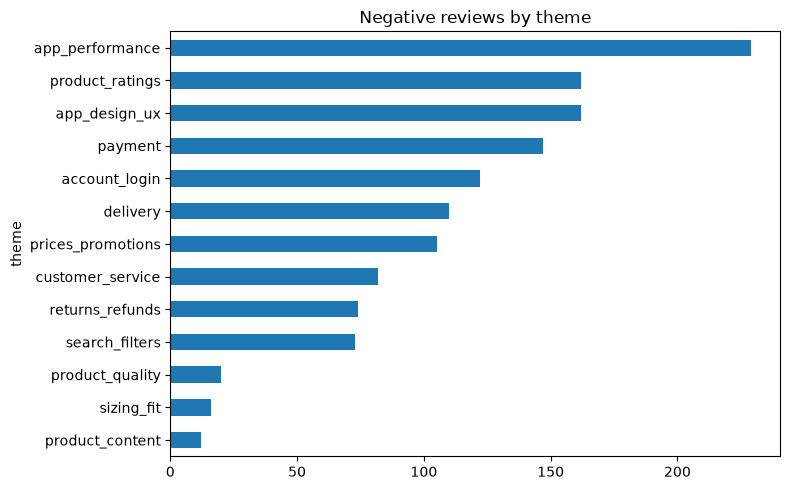

In [2]:
neg[neg['theme'] != 'other']['theme'].value_counts().sort_values().plot(
    kind='barh', figsize=(8,5), title='Negative reviews by theme')
plt.tight_layout(); plt.savefig('../docs/charts/1_complaints.png', dpi=150); plt.show()

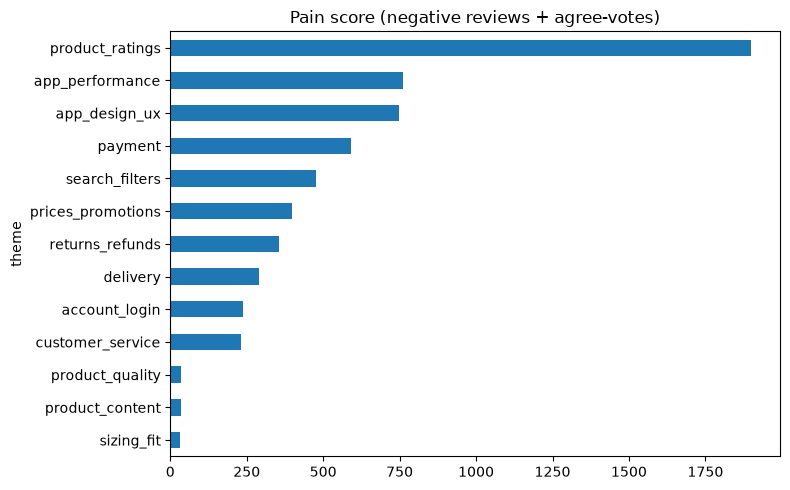

In [3]:
neg['weight'] = 1 + neg['thumbsUpCount']
neg[neg['theme'] != 'other'].groupby('theme')['weight'].sum().sort_values().plot(
    kind='barh', figsize=(8,5), title='Pain score (negative reviews + agree-votes)')
plt.tight_layout(); plt.savefig('../docs/charts/2_pain_score.png', dpi=150); plt.show()

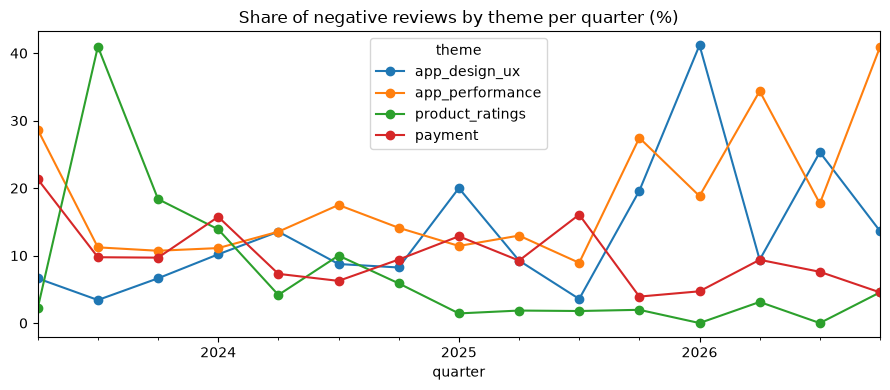

In [4]:
neg['quarter'] = neg['at'].dt.to_period('Q')
share = pd.crosstab(neg['quarter'], neg['theme'], normalize='index') * 100
share[['app_design_ux','app_performance','product_ratings','payment']].plot(
    marker='o', figsize=(9,4), title='Share of negative reviews by theme per quarter (%)')
plt.tight_layout(); plt.savefig('../docs/charts/3_trend.png', dpi=150); plt.show()

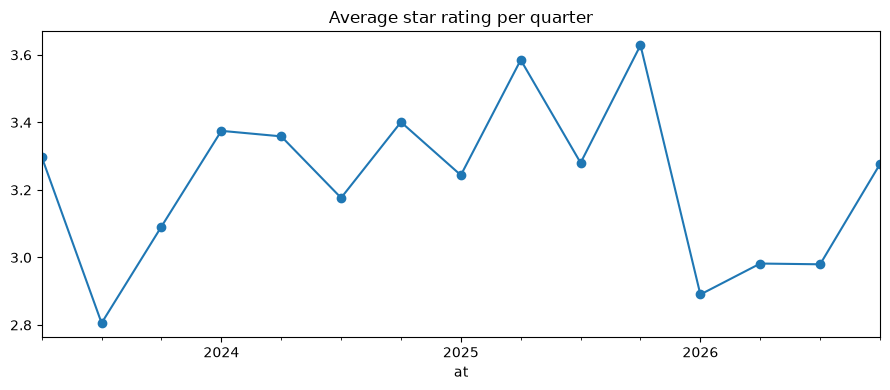

In [5]:
df.groupby(df['at'].dt.to_period('Q'))['score'].mean().plot(
    marker='o', figsize=(9,4), title='Average star rating per quarter')
plt.tight_layout(); plt.savefig('../docs/charts/4_rating.png', dpi=150); plt.show()

In [6]:
requests = df['feature_request'].dropna()
print(len(requests), "feature requests")
requests.to_csv('../data/feature_requests.csv', index=False)

230 feature requests


In [7]:
df.groupby(df['at'].dt.to_period('Q')).size()

at
2023Q2    319
2023Q3    350
2023Q4    404
2024Q1    256
2024Q2    237
2024Q3    170
2024Q4    217
2025Q1    160
2025Q2    147
2025Q3    132
2025Q4    140
2026Q1    155
2026Q2    111
2026Q3    148
2026Q4     47
Freq: Q-DEC, dtype: int64

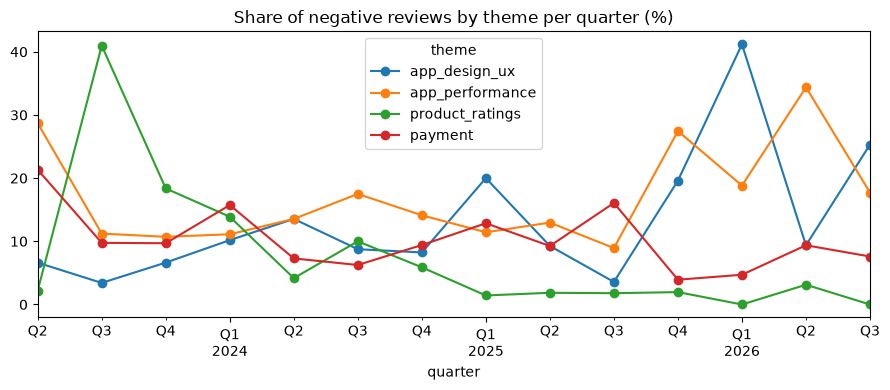

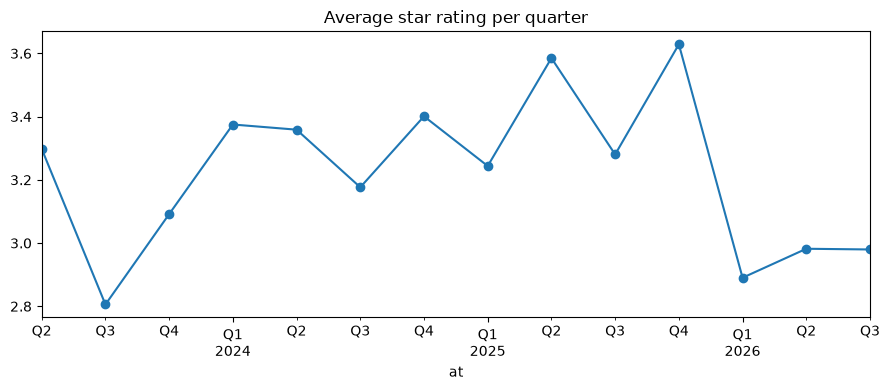

In [8]:
cutoff = pd.Period('2026Q4')

neg_q = neg[neg['quarter'] < cutoff]
share = pd.crosstab(neg_q['quarter'], neg_q['theme'], normalize='index') * 100
share[['app_design_ux','app_performance','product_ratings','payment']].plot(
    marker='o', figsize=(9,4), title='Share of negative reviews by theme per quarter (%)')
plt.tight_layout(); plt.savefig('../docs/charts/3_trend.png', dpi=150); plt.show()

df_q = df[df['at'].dt.to_period('Q') < cutoff]
df_q.groupby(df_q['at'].dt.to_period('Q'))['score'].mean().plot(
    marker='o', figsize=(9,4), title='Average star rating per quarter')
plt.tight_layout(); plt.savefig('../docs/charts/4_rating.png', dpi=150); plt.show()

In [9]:
recent = df[(df['at'] >= '2025-01-01') & (df['sentiment'] == 'negative')]
print(len(recent), "negative reviews since 2025")
recent['theme'].value_counts()

481 negative reviews since 2025


theme
app_design_ux        95
app_performance      95
account_login        43
payment              42
delivery             35
returns_refunds      35
prices_promotions    33
search_filters       30
customer_service     27
other                17
product_quality      12
product_ratings       7
sizing_fit            6
product_content       4
Name: count, dtype: int64

In [10]:
rice = pd.DataFrame({
    'feature':    ['App stability & checkout reliability', 'Invoice status page', 'Home button / navigation',
                   'Search filters', 'Verified fit feedback', 'Dark mode', 'Carrier choice'],
    'reach':      [95, 42, 95, 30, 17, 34, 35],
    'impact':     [3, 2, 1, 1, 2, 0.5, 1],
    'confidence': [0.8, 1.0, 0.5, 0.8, 0.5, 0.8, 0.5],
    'effort':     [3, 1.5, 1, 2, 2, 2, 3]
})
rice['score'] = (rice.reach * rice.impact * rice.confidence / rice.effort).round(1)
rice = rice.sort_values('score', ascending=False)
rice.to_csv('../data/rice.csv', index=False)
rice

,feature,reach,impact,confidence,effort,score
0,App stability & checkout reliability,95,3.0,0.8,3.0,76.0
1,Invoice status page,42,2.0,1.0,1.5,56.0
2,Home button / navigation,95,1.0,0.5,1.0,47.5
3,Search filters,30,1.0,0.8,2.0,12.0
4,Verified fit feedback,17,2.0,0.5,2.0,8.5
5,Dark mode,34,0.5,0.8,2.0,6.8
6,Carrier choice,35,1.0,0.5,3.0,5.8


In [11]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
effect = proportion_effectsize(0.485, 0.455)
print(round(NormalIndPower().solve_power(effect, alpha=0.05, power=0.8)), "users per group")

4343 users per group
